# 基于DeepAgents + Skills的Text2SQL实战

In [1]:
import os
import sys

from deepagents import create_deep_agent
from deepagents.backends import FilesystemBackend
from dotenv import load_dotenv
from langchain_anthropic import ChatAnthropic
from langchain_community.agent_toolkits import SQLDatabaseToolkit
from langchain_community.utilities import SQLDatabase
from rich.console import Console
from rich.panel import Panel

# 加载环境变量
load_dotenv()

True

In [2]:
console = Console()

In [3]:
# 获取当前的目录
base_dir = os.getcwd()

# 连接数据库
db_path = os.path.join(base_dir, "chinook.db")
db = SQLDatabase.from_uri(f"sqlite:///{db_path}", sample_rows_in_table_info=3)

In [7]:
# 初始化大模型Client
model = ChatAnthropic(
    api_key=os.getenv("API_KEY"),
    base_url=os.getenv("BASE_URL"),
    model=os.getenv("MODEL_ID"),
    temperature=0
)

In [8]:
model.profile

{'max_input_tokens': 200000,
 'max_output_tokens': 64000,
 'text_inputs': True,
 'image_inputs': True,
 'audio_inputs': False,
 'pdf_inputs': True,
 'video_inputs': False,
 'text_outputs': True,
 'image_outputs': False,
 'audio_outputs': False,
 'video_outputs': False,
 'reasoning_output': True,
 'tool_calling': True,
 'image_url_inputs': True,
 'pdf_tool_message': True,
 'image_tool_message': True,
 'structured_output': False}

In [9]:
# Create SQL toolkit and get tools (Langchain内置的工具包)
toolkit = SQLDatabaseToolkit(db=db, llm=model)
sql_tools = toolkit.get_tools()
print("====================SQL Tools=====================")
for tool in sql_tools:
    print(f"NAME: {tool.name}\t", tool.to_json())
    print("="*50)

====================SQL Tools=====================
NAME: sql_db_query	 {'lc': 1, 'type': 'not_implemented', 'id': ['langchain_community', 'tools', 'sql_database', 'tool', 'QuerySQLDatabaseTool'], 'repr': 'QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column \'xxxx\' in \'field list\', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x10f8705f0>)', 'name': 'sql_db_query'}
NAME: sql_db_schema	 {'lc': 1, 'type': 'not_implemented', 'id': ['langchain_community', 'tools', 'sql_database', 'tool', 'InfoSQLDatabaseTool'], 'repr': "InfoSQLDatabaseTool(description='Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those

In [10]:
# 创建并返回一个text2SQL的DeepAgents
agent = create_deep_agent(
    model=model,
    memory=["./AGENTS.md"],  # Agent身份和主Prompt
    skills=[
        "./skills/"
    ],  # 专用skills (query-writing, schema-exploration)
    tools=sql_tools,  # SQL database tools
    subagents=[],  # No subagents needed
    backend=FilesystemBackend(root_dir=base_dir, virtual_mode=True),  # 持久化存储
)

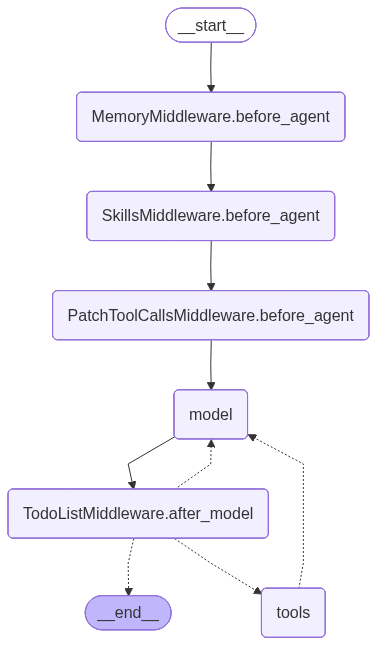

In [11]:
from IPython.display import Image, display

# Show the agent
display(Image(agent.get_graph().draw_mermaid_png()))

# 简单查询

In [12]:
# 输入的query
question = "销量最好的5个歌手是谁?"
console.print(
    Panel(f"[bold cyan]Question:[/bold cyan] {question}", border_style="cyan")
)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Question: 销量最好的5个歌手是谁?                                                                                │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [13]:
# 调用Agent
result = agent.invoke(
    {"messages": [{"role": "user", "content": question}]}
)

In [11]:
# 抽取并展示答案
final_message = result["messages"][-1]
answer = (
    final_message.content
    if hasattr(final_message, "content")
    else str(final_message)
)

console.print(
    Panel(f"[bold green]Answer:[/bold green]\n\n{answer}", border_style="green")
)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Answer:                                                                                                         │
│                                                                                                                 │
│ 根据数据库查询结果，**销量最好的5个歌手**是：                                                                   │
│                                                                                                                 │
│ 1. **Iron Maiden** - 140张销量                                                                                  │
│ 2. **U2** - 107张销量                                                                                           │
│ 3. **Metallica** - 91张销量                                                                                     │
│ 4. **Led Zeppelin** - 87张销量                                                                                  │
│ 5. **Os Paralamas Do Sucesso** - 45张销量                                                                       │
│                                                                                                                 │
│ 这些销量数据是基于InvoiceLine表中的实际购买记录统计得出的。Iron                                                 │
│ Maiden以140张的销量遥遥领先，U2和Metallica分列第二、三位。                                                      │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

# 复杂查询

In [14]:
# 输入的query
question = "哪位员工创造的收入最多？这些收入来自哪些国家？"
console.print(
    Panel(f"[bold cyan]Question:[/bold cyan] {question}", border_style="cyan")
)

# 调用Agent
result = agent.invoke(
    {"messages": [{"role": "user", "content": question}]}
)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Question: 哪位员工创造的收入最多？这些收入来自哪些国家？                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [15]:
# 抽取并展示答案
final_message = result["messages"][-1]
answer = (
    final_message.content
    if hasattr(final_message, "content")
    else str(final_message)
)

console.print(
    Panel(f"[bold green]Answer:[/bold green]\n\n{answer}", border_style="green")
)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Answer:                                                                                                         │
│                                                                                                                 │
│ ## 查询结果                                                                                                     │
│                                                                                                                 │
│ **收入最高的员工是：Jane Peacock**                                                                              │
│ - 职位：Sales Support Agent（销售支持专员）                                                                     │
│ - 总收入：**$833.04**                                                                                           │
│                                                                                                                 │
│ **Jane Peacock 的收入来源国家分布（前10名）：**                                                                 │
│                                                                                                                 │
│ | 国家 | 收入金额 | 客户数 | 订单数 |                                                                           │
│ |------|---------|--------|--------|                                                                            │
│ | 加拿大 (Canada) | $191.10 | 5 | 35 |                                                                          │
│ | 美国 (USA) | $119.86 | 3 | 21 |                                                                               │
│ | 德国 (Germany) | $81.24 | 2 | 14 |                                                                            │
│ | 法国 (France) | $80.24 | 2 | 14 |                                                                             │
│ | 巴西 (Brazil) | $77.24 | 2 | 14 |                                                                             │
│ | 印度 (India) | $75.26 | 2 | 13 |                                                                              │
│ | 英国 (United Kingdom) | $75.24 | 2 | 14 |                                                                     │
│ | 爱尔兰 (Ireland) | $45.62 | 1 | 7 |                                                                           │
│ | 匈牙利 (Hungary) | $45.62 | 1 | 7 |                                                                           │
│ | 芬兰 (Finland) | $41.62 | 1 | 7 |                                                                             │
│                                                                                                                 │
│ **主要发现：**                                                                                                  │
│ - Jane Peacock 的收入主要来自**加拿大**（占总收入的23%）和**美国**（占14%）                                     │
│ - 她负责支持来自多个国家的客户，收入分布较为广泛                                                                │
│ - 其他两位销售支持专员的收入分别为：Margaret Park ($775.40) 和 Steve Johnson ($720.16)                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯